# Part 3 | Teunter–Syntetos–Babai (TSB)
### A guided tutorial in intermittent demand forecasting

**Learning goals:** understand demand occurrence, estimate probability from scratch, calculate the TSB forecast manually, and explain how it reacts to declining demand and possible obsolescence.

This is a continuation of the Croston and SBA notebooks. We use monthly demand for a spare part, with $\alpha=0.2$ and $\beta=0.2$. No prior Python knowledge is needed to follow the worked Markdown calculations. Run the code cells in order to reproduce the tables and charts.

## 1. Why do we need TSB?
Our original six-month demand history is 10, 0, 0, 12, 0, 8 units. Imagine that July through December are also observed to have zero demand.

Croston and SBA update their demand size and interval estimates only when positive demand occurs. At the end of June, their forecasts are 6.53 and 5.87 units/month respectively. Six further observed zero-demand months leave both forecasts unchanged. This can contribute to excess inventory when demand is declining.

TSB (2011) addresses this by updating the **probability of demand in every observed period**, even when demand is zero.

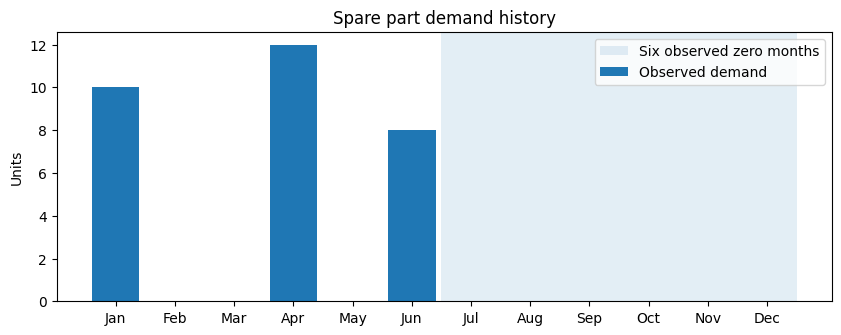

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
demand = [10,0,0,12,0,8,0,0,0,0,0,0]
alpha = beta = 0.2
fig, ax = plt.subplots(figsize=(10,3.5))
ax.bar(months,demand,label='Observed demand')
ax.axvspan(5.5,11.5,alpha=.12,label='Six observed zero months')
ax.set(ylabel='Units',title='Spare part demand history'); ax.legend(); plt.show()

## 2. Croston's interval P versus TSB's probability p
| Quantity | Croston / SBA | TSB |
|---|---|---|
| Estimated size $Z$ | Units per positive period | Units per positive period |
| Estimated interval $P$ | Periods between positive demands | Not used |
| Estimated probability $p$ | Not directly estimated | Probability per period, 0 to 1 |
| Forecast | $Z/P$ (SBA applies a correction) | $Zp$ |

### Simple solved example
Suppose demand is 12 units every three months. The long-run frequency is one occurrence in three periods. If $P=3$, Croston gives $12/3=4$ units/month. If $p=1/3$, TSB gives $12(1/3)=4$ units/month. The two estimates agree in this simplified example, but in general TSB smooths probability directly, not the reciprocal of Croston's smoothed interval.

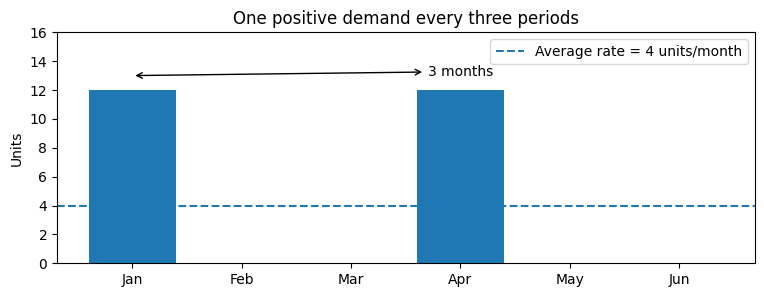

In [2]:
fig, ax = plt.subplots(figsize=(9,3))
ax.bar(months[:6],[12,0,0,12,0,0]); ax.axhline(4,linestyle='--',label='Average rate = 4 units/month')
ax.annotate('3 months',xy=(0,13),xytext=(3,13),arrowprops={'arrowstyle':'<->'},ha='center')
ax.set(ylim=(0,16),ylabel='Units',title='One positive demand every three periods'); ax.legend(); plt.show()

## 3. Demand occurrence indicator (I)
Convert the demand quantity into a binary indicator:
$$I_t=\begin{cases}1 & D_t>0\\0 & D_t=0\end{cases}$$
Whether demand is 10 or 1,000 units, its indicator is 1. We measure whether demand occurs, not how much occurs.

| Month | Actual demand D | Occurrence I |
|---|---:|---:|
| Jan | 10 | 1 |
| Feb | 0 | 0 |
| Mar | 0 | 0 |
| Apr | 12 | 1 |
| May | 0 | 0 |
| Jun | 8 | 1 |

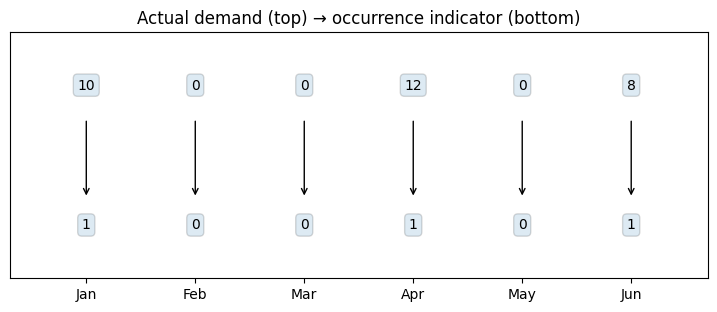

In [3]:
fig, ax = plt.subplots(figsize=(9,3.2))
x = np.arange(6)
for j,d in enumerate(demand[:6]):
    ax.text(j,1.2,str(d),ha='center',va='center',bbox=dict(boxstyle='round',alpha=.15))
    ax.annotate('',xy=(j,.35),xytext=(j,.95),arrowprops=dict(arrowstyle='->'))
    ax.text(j,.15,str(int(d>0)),ha='center',va='center',bbox=dict(boxstyle='round',alpha=.15))
ax.set(xlim=(-.7,5.7),ylim=(-.25,1.6),xticks=x,xticklabels=months[:6],yticks=[],title='Actual demand (top) → occurrence indicator (bottom)'); plt.show()

## 4. Two smoothing parameters
- $\alpha=0.2$: weight given to new positive demand size when updating Z.
- $\beta=0.2$: weight given to the current occurrence indicator when updating p.

The remaining weight is given to the previous estimate. These are illustrative choices, not universal optimal values. A larger beta makes the model react more quickly to changes in frequency.

## 5. Calculate estimated demand size Z from scratch
The size update is identical to Croston:
$$Z_t=\begin{cases}\alpha D_t+(1-\alpha)Z_{t-1}&D_t>0\\Z_{t-1}&D_t=0\end{cases}$$
Initialize January at its first positive demand, 10 units. There is no smoothing calculation at initialization.

**February and March:** demand is zero, so carry forward 10.

**April:** demand is 12. Give 80% weight to the previous estimate and 20% to new demand:
$$Z_{Apr}=0.8(10)+0.2(12)=8+2.4=10.4$$
**May:** demand is zero, so carry forward 10.4.

**June:** demand is 8:
$$Z_{Jun}=0.8(10.4)+0.2(8)=8.32+1.6=9.92$$

| Month | D | Z calculation | Z |
|---|---:|---|---:|
| Jan | 10 | Initialize | 10 |
| Feb | 0 | Carry forward | 10 |
| Mar | 0 | Carry forward | 10 |
| Apr | 12 | 0.8 × 10 + 0.2 × 12 | 10.4 |
| May | 0 | Carry forward | 10.4 |
| Jun | 8 | 0.8 × 10.4 + 0.2 × 8 | 9.92 |

Z is conditional demand size, **not monthly forecast demand**.

## 6. Calculate estimated demand probability p from scratch
$$\boxed{p_t=\beta I_t+(1-\beta)p_{t-1}}$$
Here $p_{t-1}$ is the previous smoothed probability, $I_t$ is the new occurrence (0 or 1), and $\beta$ is the smoothing weight. Unlike Croston's interval P, p is updated each month after initialization.

### January — first positive demand
We initialize $p_{Jan}=1$ (100%). This is an assumption for this example, not proof that future demand is certain.

### February — no demand
$I=0$, previous probability is 1:
$$p_{Feb}=0.2(0)+0.8(1)=0.8=80\%$$
### March — no demand again
$$p_{Mar}=0.2(0)+0.8(0.8)=0.64=64\%$$
### April — demand occurs
$I=1$, previous probability is 0.64:
$$p_{Apr}=0.2(1)+0.8(0.64)=0.2+0.512=0.712=71.2\%$$
### May — no demand
$$p_{May}=0.2(0)+0.8(0.712)=0.5696=56.96\%$$
### June — demand occurs
$$p_{Jun}=0.2(1)+0.8(0.5696)=0.2+0.45568=0.65568=65.568\%$$

The probability moves toward 1 when demand occurs and toward 0 when it does not. For zero demand the new probability is simply the previous probability multiplied by $1-\beta$.

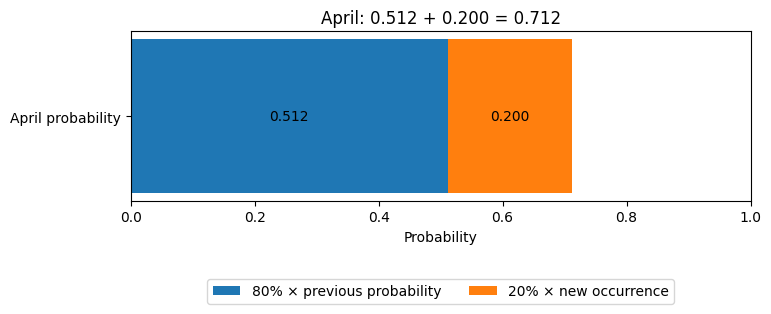

In [4]:
fig, ax = plt.subplots(figsize=(8,2.2))
ax.barh(['April probability'],[.512],label='80% × previous probability')
ax.barh(['April probability'],[.2],left=[.512],label='20% × new occurrence')
ax.text(.256,0,'0.512',ha='center',va='center'); ax.text(.612,0,'0.200',ha='center',va='center')
ax.set(xlim=(0,1),xlabel='Probability',title='April: 0.512 + 0.200 = 0.712'); ax.legend(loc='upper center',bbox_to_anchor=(.5,-.42),ncol=2); plt.show()

## 7. Reusable Python implementation
The function below records states **after** the current observation. The column `TSB_next` is the forecast for the next period; `TSB_one_step` is shifted by one period so it can be compared to actual demand without look-ahead leakage.

For consistency, initialize Z to the first positive demand and p to 1 by default. Leading zero periods have undefined states until a positive demand arrives. All-zero histories therefore have no initialized forecast in this tutorial; a production system needs a separate policy. Missing or negative demand is rejected rather than silently treated as zero.

In [5]:
def tsb(values, alpha=.2, beta=.2, initial_probability=1.0, labels=None):
    d = np.asarray(values,dtype=float)
    if d.ndim != 1 or not len(d) or not np.isfinite(d).all() or (d<0).any():
        raise ValueError('Supply a nonempty sequence of finite nonnegative demands.')
    if not (0<alpha<=1 and 0<beta<=1 and 0<=initial_probability<=1):
        raise ValueError('Invalid smoothing weights or initial probability.')
    z=p=np.nan
    rows=[]
    for value in d:
        i=int(value>0)
        if np.isnan(z):
            if i: z,p=value,initial_probability
        else:
            p=beta*i+(1-beta)*p
            if i: z=alpha*value+(1-alpha)*z
        rows.append((value,i,z,p,z*p))
    result=pd.DataFrame(rows,columns=['Demand','I','Z','p','TSB_next'],index=labels)
    result['TSB_one_step']=result['TSB_next'].shift(1)
    return result
six=tsb(demand[:6],labels=months[:6]); display(six.round(5))

,Demand,I,Z,p,TSB_next,TSB_one_step
Jan,10.0,1,10.00,1.00000,10.00000,NaN
Feb,0.0,0,10.00,0.80000,8.00000,10.00000
Mar,0.0,0,10.00,0.64000,6.40000,8.00000
Apr,12.0,1,10.40,0.71200,7.40480,6.40000
May,0.0,0,10.40,0.56960,5.92384,7.40480
Jun,8.0,1,9.92,0.65568,6.50435,5.92384


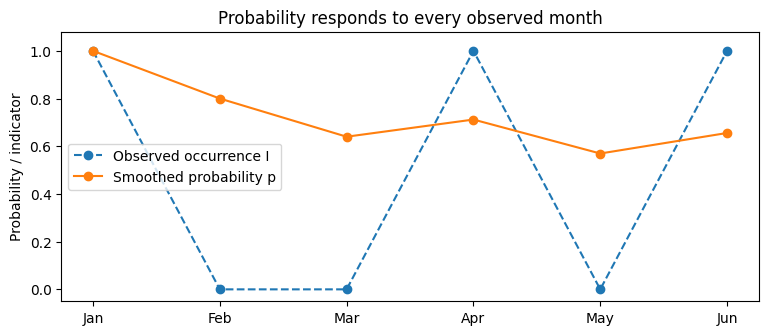

In [6]:
fig,ax=plt.subplots(figsize=(9,3.5))
ax.plot(six.index,six.I,'o--',label='Observed occurrence I')
ax.plot(six.index,six.p,'o-',label='Smoothed probability p')
ax.set(ylim=(-.05,1.08),ylabel='Probability / indicator',title='Probability responds to every observed month'); ax.legend(); plt.show()

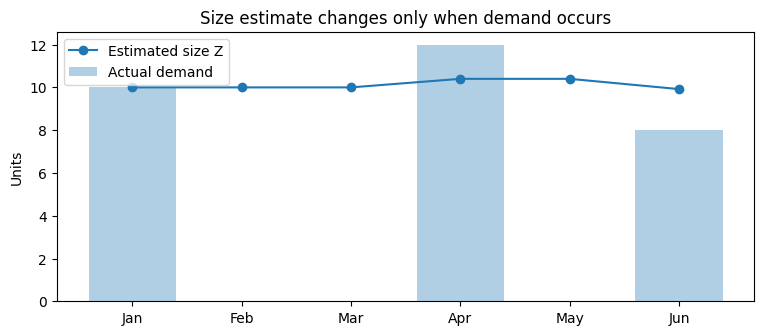

In [7]:
fig,ax=plt.subplots(figsize=(9,3.5))
ax.bar(six.index,six.Demand,alpha=.35,label='Actual demand')
ax.plot(six.index,six.Z,'o-',label='Estimated size Z')
ax.set(ylabel='Units',title='Size estimate changes only when demand occurs'); ax.legend(); plt.show()

## 8. Calculate the final TSB forecast F
$$\boxed{F_t=Z_t p_t}$$
At the end of June, Z = 9.92 units per positive demand period and p = 0.65568.
$$F_{Jun}=9.92\times0.65568=6.5043456\approx6.50\text{ units/month}$$
This is the July forecast, not the actual demand in June or a prediction that exactly 6.50 units will be ordered.

| Month | D | I | Z | p | F for next month |
|---|---:|---:|---:|---:|---:|
| Jan | 10 | 1 | 10 | 1.00000 | 10.00 |
| Feb | 0 | 0 | 10 | 0.80000 | 8.00 |
| Mar | 0 | 0 | 10 | 0.64000 | 6.40 |
| Apr | 12 | 1 | 10.4 | 0.71200 | 7.40 |
| May | 0 | 0 | 10.4 | 0.56960 | 5.92 |
| Jun | 8 | 1 | 9.92 | 0.65568 | 6.50 |

## 9. What happens after six observed zero-demand months?
In July, Z remains 9.92, while $p_{Jul}=0.8(0.65568)=0.524544$.
$$F_{Jul}=9.92(0.524544)=5.20347648$$
In August, $p_{Aug}=0.8(0.524544)=0.4196352$.
$$F_{Aug}=9.92(0.4196352)=4.162781184$$
The same update continues for each observed zero.

For n consecutive observed zero periods:
$$p_{t+n}=p_t(1-\beta)^n$$
$$\boxed{F_{t+n}=F_t(1-\beta)^n}$$
After six zeros, $6.5043456(0.8)^6\approx1.7051$ units/month. This is exponential decay, not an assumption that unobserved future demand will be zero.

In [8]:
def croston_sba(values, alpha=.2, labels=None):
    z=P=np.nan; last=None; rows=[]
    for t,d in enumerate(values):
        if d>0:
            if last is None: z,P=d,1.0
            else:
                z=alpha*d+(1-alpha)*z
                P=alpha*(t-last)+(1-alpha)*P
            last=t
        rows.append((z,P,z/P,(1-alpha/2)*z/P))
    return pd.DataFrame(rows,columns=['Croston_Z','P','Croston_next','SBA_next'],index=labels)
full=tsb(demand,labels=months).join(croston_sba(demand,labels=months))
display(full.loc['Jun':,['Demand','Z','p','Croston_next','SBA_next','TSB_next']].round(5))

,Demand,Z,p,Croston_next,SBA_next,TSB_next
Jun,8.0,9.92,0.65568,6.52632,5.87368,6.50435
Jul,0.0,9.92,0.52454,6.52632,5.87368,5.20348
Aug,0.0,9.92,0.41964,6.52632,5.87368,4.16278
Sep,0.0,9.92,0.33571,6.52632,5.87368,3.33022
Oct,0.0,9.92,0.26857,6.52632,5.87368,2.66418
Nov,0.0,9.92,0.21485,6.52632,5.87368,2.13134
Dec,0.0,9.92,0.17188,6.52632,5.87368,1.70508


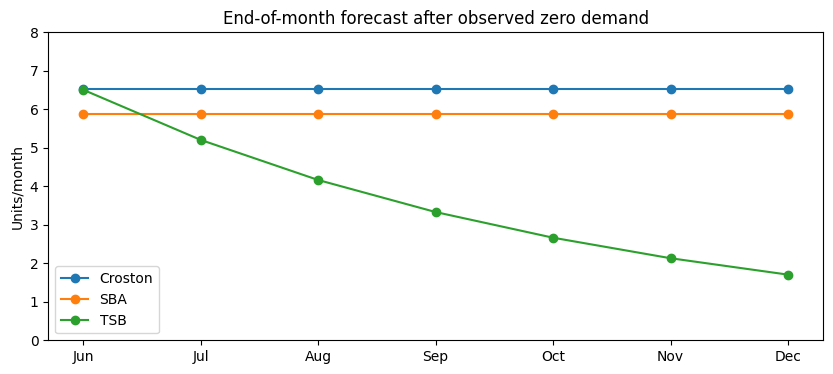

In [9]:
fig,ax=plt.subplots(figsize=(10,4))
for col,label in [('Croston_next','Croston'),('SBA_next','SBA'),('TSB_next','TSB')]:
    ax.plot(full.index[5:],full[col].iloc[5:], 'o-',label=label)
ax.set(ylim=(0,8),ylabel='Units/month',title='End-of-month forecast after observed zero demand'); ax.legend(); plt.show()

## 10. Forecast timing: observed zeros vs unknown future
At the end of June, before July demand is observed, the standard TSB point forecast for each future month is the current rate of 6.5043456 units/month (assuming no additional information). The six-month expected total at that forecast origin is six times that rate.

Only after an actual July zero is observed does the rate fall to 5.2035 for August. A declining trajectory is therefore a **conditional zero-demand scenario**, not the unconditional multi-step forecast. Do not fill unknown future months with zeros when preparing forecast inputs.

,Forecast_at_end_June,Conditional_rate_after_observed_zero
Jul,6.5043,5.2035
Aug,6.5043,4.1628
Sep,6.5043,3.3302
Oct,6.5043,2.6642
Nov,6.5043,2.1313
Dec,6.5043,1.7051


Six-month forecast at end of June: 39.0261


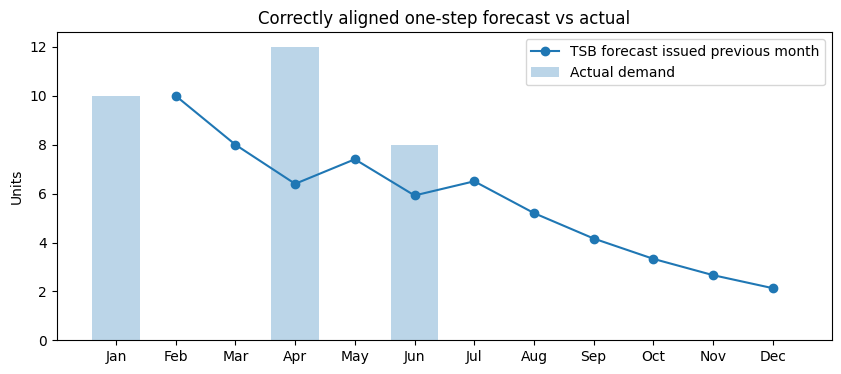

In [10]:
rate=six.TSB_next.iloc[-1]
future=pd.DataFrame({'Forecast_at_end_June':rate,'Conditional_rate_after_observed_zero':full.TSB_next.iloc[6:].values},index=months[6:])
display(future.round(4))
print('Six-month forecast at end of June:',round(6*rate,4))
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(months,demand,alpha=.3,label='Actual demand')
ax.plot(months,full.TSB_one_step,'o-',label='TSB forecast issued previous month')
ax.set(ylabel='Units',title='Correctly aligned one-step forecast vs actual'); ax.legend(); plt.show()

## 11. Guided experiment: alpha, beta and zero months
Change the values in the next code cell and rerun it. Alpha controls how fast size reacts; beta controls how fast probability reacts. The zero-month scenario is explicitly conditional on those zeros being observed.

Try beta = 0.5, then 0.05. Compare the starting forecast as well as the decay speed: beta affects the probability during training too.

Z=9.9200; starting p=0.65568; final p=0.17188
TSB: 6.5043 → 1.7051 units/month


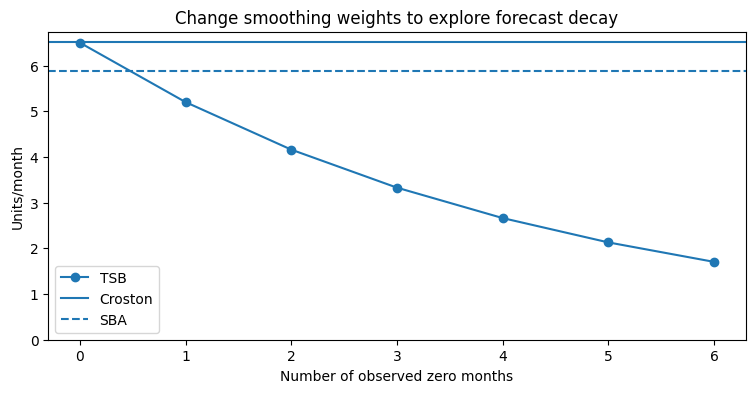

In [11]:
# Edit these three values and rerun
experiment_alpha=.2
experiment_beta=.2
zero_months=6
base=demand[:6]
r=tsb(base,experiment_alpha,experiment_beta).iloc[-1]
comp=croston_sba(base,experiment_alpha).iloc[-1]
k=np.arange(zero_months+1)
p_decay=r.p*(1-experiment_beta)**k
f_decay=r.Z*p_decay
print(f'Z={r.Z:.4f}; starting p={r.p:.5f}; final p={p_decay[-1]:.5f}')
print(f'TSB: {f_decay[0]:.4f} → {f_decay[-1]:.4f} units/month')
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(k,f_decay,'o-',label='TSB'); ax.axhline(comp.Croston_next,label='Croston'); ax.axhline(comp.SBA_next,linestyle='--',label='SBA')
ax.set(xlabel='Number of observed zero months',ylabel='Units/month',ylim=(0,None),title='Change smoothing weights to explore forecast decay'); ax.legend(); plt.show()

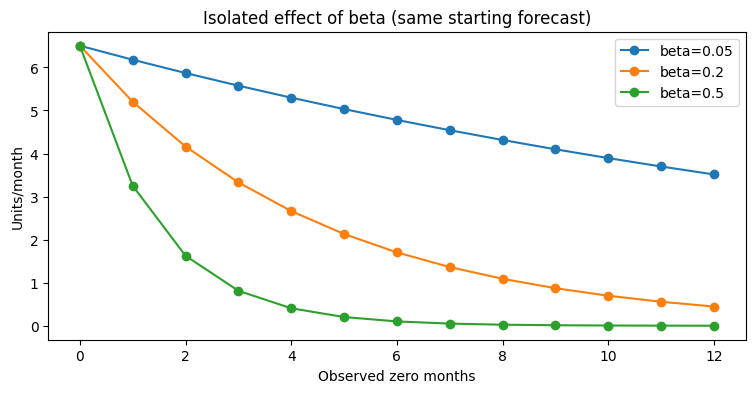

In [12]:
fig,ax=plt.subplots(figsize=(9,4))
for bval in [.05,.2,.5]:
    # Hold starting forecast fixed to isolate the effect of beta on decay.
    k=np.arange(13); ax.plot(k,rate*(1-bval)**k,'o-',label=f'beta={bval}')
ax.set(xlabel='Observed zero months',ylabel='Units/month',title='Isolated effect of beta (same starting forecast)'); ax.legend(); plt.show()

## 12. TSB process diagram
Historical demand is split into size and occurrence streams. Smooth the size on positive demand, smooth occurrence every period, then multiply the two estimates.

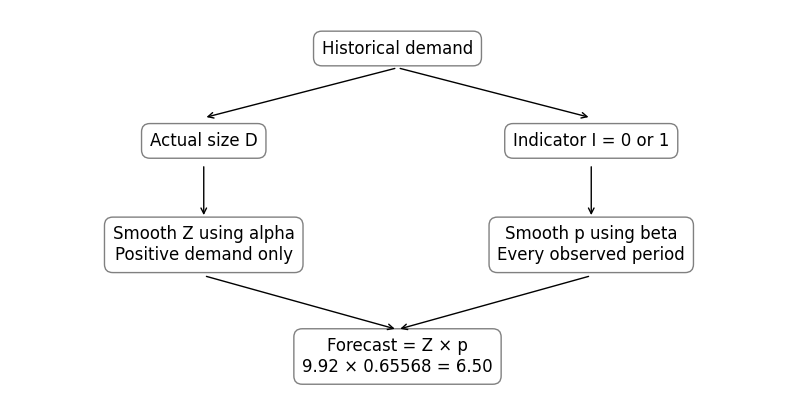

In [13]:
fig,ax=plt.subplots(figsize=(10,5)); ax.axis('off')
boxes=[(.5,.9,'Historical demand'),(.25,.66,'Actual size D'),(.75,.66,'Indicator I = 0 or 1'),(.25,.39,'Smooth Z using alpha\nPositive demand only'),(.75,.39,'Smooth p using beta\nEvery observed period'),(.5,.1,'Forecast = Z × p\n9.92 × 0.65568 = 6.50')]
for x,y,s in boxes: ax.text(x,y,s,ha='center',va='center',fontsize=12,bbox=dict(boxstyle='round,pad=.5',facecolor='white',edgecolor='gray'),transform=ax.transAxes)
for x1,y1,x2,y2 in [(.5,.85,.25,.72),(.5,.85,.75,.72),(.25,.60,.25,.46),(.75,.60,.75,.46),(.25,.31,.5,.17),(.75,.31,.5,.17)]: ax.annotate('',xy=(x2,y2),xytext=(x1,y1),xycoords='axes fraction',arrowprops=dict(arrowstyle='->'))
plt.show()

## 13. Compare Croston, SBA and TSB
| Feature | Croston | SBA | TSB |
|---|---|---|---|
| Demand size | Z | Z | Z |
| Frequency representation | Interval P | Interval P | Probability p |
| Formula | Z/P | (1−alpha/2) Z/P | Zp |
| Updates on observed zeros | No | No | Probability only |
| June rate | 6.53 | 5.87 | 6.50 |
| December rate after 6 zeros | 6.53 | 5.87 | 1.71 |

TSB is worth testing for declining demand frequency and obsolescence risk, but zero sales may also reflect stockouts, missing records or seasonal gaps. TSB does not identify the cause, and its forecast is not an obsolescence decision. Tune weights and initialization using rolling-origin backtesting. Compare both forecast performance and inventory outcomes; avoid percentage errors that divide by zero actual demand.

## 14. Practice questions with worked solutions
**Q1.** Previous probability = 0.4, beta = 0.2, current demand = 0. Find the new probability.

**Solution:** $p=0.2(0)+0.8(0.4)=0.32$.

**Q2.** The next period has demand 15. Previous Z = 10, alpha = 0.2, and previous probability = 0.32. Find Z, p and F.

**Solution:** $Z=0.8(10)+0.2(15)=11$; $p=0.8(0.32)+0.2(1)=0.456$; $F=11(0.456)=5.016$ units/period.

**Q3.** Starting at F = 5.016, beta = 0.2, observe three consecutive zeros. Find the new forecast.

**Solution:** $F=5.016(0.8)^3=2.568192$ units/period. Z remains 11.

**Q4.** If the next three months are unknown rather than observed zero, what forecast is issued now?

**Solution:** 5.016 units per future period under the standard constant-rate point forecast, not the conditional decay path.

In [14]:
assert np.allclose(six.Z,[10,10,10,10.4,10.4,9.92])
assert np.allclose(six.p,[1,.8,.64,.712,.5696,.65568])
assert np.isclose(rate,6.5043456)
assert np.isclose(full.TSB_next.iloc[-1],rate*.8**6)
assert np.allclose(full.Croston_next.iloc[5:],9.92/1.52)
assert np.allclose(full.SBA_next.iloc[5:],.9*9.92/1.52)
assert full.p.between(0,1).all()
assert np.isnan(tsb([0,0]).TSB_next.iloc[-1])
assert np.isnan(six.TSB_one_step.iloc[0])
assert np.allclose(six.TSB_one_step.iloc[1:],six.TSB_next.iloc[:-1])
assert np.isclose(5.016*.8**3,2.568192)
print('All numerical and forecast-alignment checks passed.')

All numerical and forecast-alignment checks passed.


## 15. Key takeaways and reference
- Croston estimates demand size and the interval between positive periods.
- SBA applies an approximate bias correction to Croston.
- TSB estimates size and probability, updating probability even on zero demand.
- The final forecast is a demand rate per period, not a prediction of the exact next order.
- Initialization in this tutorial: Z = first positive demand, p = 1, Croston P = 1, alpha = beta = 0.2. These choices are for continuity with the earlier notebooks and should be validated for real SKUs.

**Reference:** Teunter, R. H., Syntetos, A. A., & Babai, M. Z. (2011). Intermittent demand: Linking forecasting to inventory obsolescence. *European Journal of Operational Research*, 214(3), 606–615. https://doi.org/10.1016/j.ejor.2011.05.018